In [26]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("manas29/micc-f2000")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/micc-f2000


In [27]:
import os
import numpy as np
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import RMSprop
import matplotlib.pyplot as plt

In [28]:
IMG_SIZE = 128
DATASET_PATH = "/kaggle/input/micc-f2000/MICC-F2000"

In [29]:
def load_and_label_images(path):
    images, labels = [], []
    for filename in os.listdir(path):
        if not filename.endswith(".jpg"):
            continue
        file_path = os.path.join(path, filename)
        img = cv2.imread(file_path)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        img = img / 255.0  # Normalize

        # Label logic: forged if 'tamp' in name or '_2_' in name
        if 'tamp' in filename or '_2_' in filename:
            label = 1  # Forged
        else:
            label = 0  # Original

        images.append(img)
        labels.append(label)
    return np.array(images), np.array(labels)

In [30]:
X, y = load_and_label_images(DATASET_PATH)
print("Dataset loaded:", X.shape, y.shape)

Dataset loaded: (2000, 128, 128, 3) (2000,)


In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [32]:
def build_model():
    model = Sequential()
    model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)))
    model.add(MaxPooling2D((2, 2)))
    
    model.add(Conv2D(64, (3, 3), activation='relu'))
    model.add(MaxPooling2D((2, 2)))
    
    model.add(Conv2D(128, (3, 3), activation='relu'))
    model.add(MaxPooling2D((2, 2)))
    
    model.add(Flatten())
    model.add(Dense(128, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))  # binary classification

    model.compile(optimizer=RMSprop(), loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_model()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1750663276.930881      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [38]:
history = model.fit(X_train, y_train, epochs=100, batch_size=16, validation_data=(X_test, y_test))


Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9773 - loss: 0.0921 - val_accuracy: 0.9675 - val_loss: 0.1883
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9805 - loss: 0.0756 - val_accuracy: 0.9575 - val_loss: 0.2362
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9753 - loss: 0.0912 - val_accuracy: 0.9625 - val_loss: 0.2471
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9718 - loss: 0.1047 - val_accuracy: 0.9675 - val_loss: 0.1827
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9817 - loss: 0.0697 - val_accuracy: 0.9650 - val_loss: 0.1833
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9723 - loss: 0.0972 - val_accuracy: 0.9575 - val_loss: 0.2870
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9817 - loss: 0.0699 - val_accuracy: 0.9650 - val_loss: 0.2015
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9763 - loss: 0.0897 - val_acc

In [39]:
loss, acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {acc * 100:.2f}%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9566 - loss: 0.4755
Test Accuracy: 96.00%


In [40]:
y_pred = (model.predict(X_test) > 0.5).astype("int32")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.95      0.97       246
           1       0.92      0.98      0.95       154

    accuracy                           0.96       400
   macro avg       0.95      0.96      0.96       400
weighted avg       0.96      0.96      0.96       400



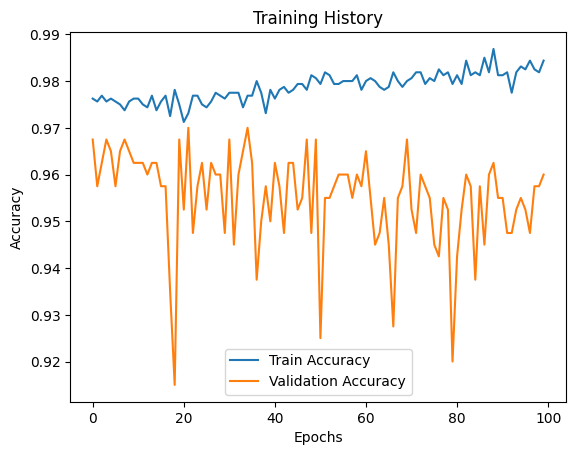

In [41]:
plt.plot(history.history['accuracy'], label="Train Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")
plt.title("Training History")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()